<a href="https://colab.research.google.com/github/AbbunapuramVijay-1234/Data-Analytics/blob/main/DA_Analytics_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset using Pandas
file_path = '/content/house_prices (1) (1) (1) (1) - house_prices (1) (1) (1) (1).csv'
df = pd.read_csv(file_path)

# Display the first few rows of the dataset
display(df.head())

,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,...,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,YrSold,SalePrice
0,65,8450,7,5,2003,2003,196,706,0,150,...,548,0,61,0,0,0,0,0,2008,208500
1,80,9600,6,8,1976,1976,0,978,0,284,...,460,298,0,0,0,0,0,0,2007,181500
2,68,11250,7,5,2001,2002,162,486,0,434,...,608,0,42,0,0,0,0,0,2008,223500
3,60,9550,7,5,1915,1970,0,216,0,540,...,642,0,35,272,0,0,0,0,2006,140000
4,84,14260,8,5,2000,2000,350,655,0,490,...,836,192,84,0,0,0,0,0,2008,250000


In [2]:
# Display summary statistics (mean, median, std, etc.) for numerical columns
summary_stats = df.describe().T
display(summary_stats)

,count,mean,std,min,25%,50%,75%,max
LotFrontage,1379.0,57.766497,35.038221,0.0,41.5,64.0,79.0,313.0
LotArea,1379.0,10695.812183,10214.702133,1300.0,7741.0,9591.0,11708.5,215245.0
OverallQual,1379.0,6.187092,1.345780,2.0,5.0,6.0,7.0,10.0
OverallCond,1379.0,5.577955,1.081031,2.0,5.0,5.0,6.0,9.0
YearBuilt,1379.0,1972.958666,29.379883,1880.0,1955.0,1976.0,2001.0,2010.0
YearRemodAdd,1379.0,1985.435098,20.444852,1950.0,1968.0,1994.0,2004.0,2010.0
MasVnrArea,1379.0,108.364757,184.195220,0.0,0.0,0.0,170.5,1600.0
BsmtFinSF1,1379.0,455.578680,459.691379,0.0,0.0,400.0,732.0,5644.0
BsmtFinSF2,1379.0,48.102248,164.324665,0.0,0.0,0.0,0.0,1474.0
BsmtUnfSF,1379.0,570.765047,443.677845,0.0,228.0,476.0,811.0,2336.0


In [3]:
# Calculate point estimates (mean, variance) for at least two numerical columns
# We will use columns like 'SalePrice' and 'GrLivArea' (or equivalent numerical columns present in the dataset)
# Let's dynamically find two numerical columns to avoid column name errors if they differ slightly.
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
col1 = 'SalePrice' if 'SalePrice' in num_cols else num_cols[0]
col2 = 'GrLivArea' if 'GrLivArea' in num_cols else (num_cols[1] if len(num_cols) > 1 else num_cols[0])

print(f"Point Estimates for: {col1}")
print(f"  Mean: {df[col1].mean():.2f}")
print(f"  Variance: {df[col1].var():.2f}")
print(f"  Sample Size: {df[col1].count()}")
print("-" * 40)
print(f"Point Estimates for: {col2}")
print(f"  Mean: {df[col2].mean():.2f}")
print(f"  Variance: {df[col2].var():.2f}")
print(f"  Sample Size: {df[col2].count()}")

Point Estimates for: SalePrice
  Mean: 185479.51
  Variance: 6244775285.52
  Sample Size: 1379
----------------------------------------
Point Estimates for: GrLivArea
  Mean: 1534.69
  Variance: 269506.87
  Sample Size: 1379


In [4]:
# Construct a 95% confidence interval for the mean of the primary target variable (col1) using the analytical formula
selected_feature = col1
data = df[selected_feature].dropna()
mean = np.mean(data)
sem = stats.sem(data)
confidence_level = 0.95

# t-distribution confidence interval
ci_analytical = stats.t.interval(confidence_level, len(data)-1, loc=mean, scale=sem)
print(f"95% Confidence Interval (Analytical) for the mean of {selected_feature}:")
print(f"Lower Bound: {ci_analytical[0]:.2f}")
print(f"Upper Bound: {ci_analytical[1]:.2f}")

95% Confidence Interval (Analytical) for the mean of SalePrice:
Lower Bound: 181305.00
Upper Bound: 189654.03


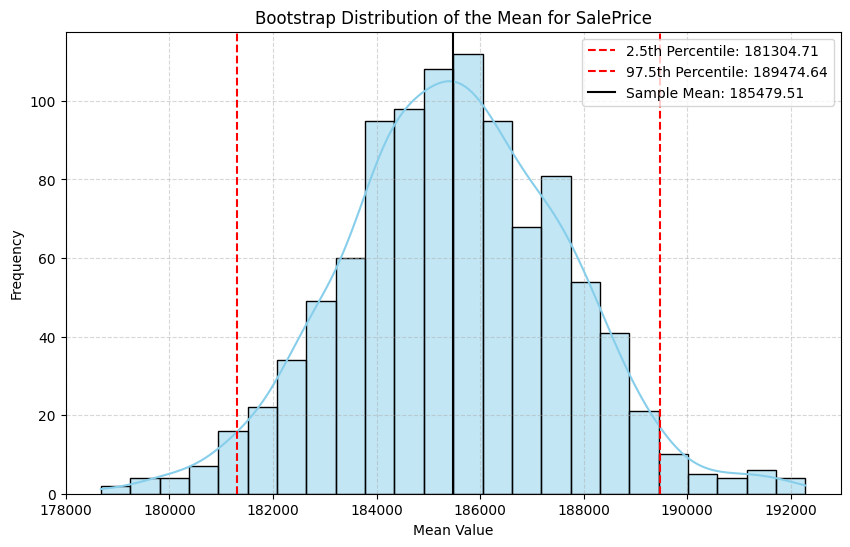

95% Confidence Interval (Bootstrap) for the mean of SalePrice:
Lower Bound: 181304.71
Upper Bound: 189474.64


In [5]:
# Construct a 95% confidence interval for the mean using a bootstrapping sampling method
np.random.seed(42)
bootstrap_means = []
n_iterations = 1000
sample_size = len(data)

for _ in range(n_iterations):
    bootstrap_sample = np.random.choice(data, size=sample_size, replace=True)
    bootstrap_means.append(np.mean(bootstrap_sample))

ci_bootstrap = np.percentile(bootstrap_means, [2.5, 97.5])

# Visualization of Bootstrap Distribution
plt.figure(figsize=(10, 6))
sns.histplot(bootstrap_means, kde=True, color='skyblue')
plt.axvline(ci_bootstrap[0], color='red', linestyle='--', label=f'2.5th Percentile: {ci_bootstrap[0]:.2f}')
plt.axvline(ci_bootstrap[1], color='red', linestyle='--', label=f'97.5th Percentile: {ci_bootstrap[1]:.2f}')
plt.axvline(mean, color='black', linestyle='-', label=f'Sample Mean: {mean:.2f}')
plt.title(f'Bootstrap Distribution of the Mean for {selected_feature}')
plt.xlabel('Mean Value')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"95% Confidence Interval (Bootstrap) for the mean of {selected_feature}:")
print(f"Lower Bound: {ci_bootstrap[0]:.2f}")
print(f"Upper Bound: {ci_bootstrap[1]:.2f}")

In [ ]:
### Statistical Summary & Inferences
'''-Point Estimates: Give us a single-valued best guess of our population parameters (e.g., sample mean and sample variance).
   -Confidence Intervals**: Show that we can be 95% confident that the true population mean lies within the calculated analytical range and bootstrap bounds. Note how closely the analytical interval and bootstrap interval align due to the Central Limit Theorem applying to a moderately large sample.'''

In [ ]:
### Population Representation Reflection
'''When evaluating if this sample represents the true population well, we must consider how the data was gathered:
1. Sample Size: If the dataset has a robust size (typically N > 100), the sample mean is a reliable estimator.
2. Selection Bias: If the house price data represents a specific city or time frame, it may not perfectly generalize to other markets or economic climates.'''